## [ReCoV](Rhttps://arxiv.org/pdf/2306.13990v2eCoV): Detecting Noisy Labels with Repeated Cross-Validations Paper Implementation

* it solved the problem of label noise in classification tasks.

* core idea:

    the algorithm designed to identify noisy labels in machine learning datasets by leveraging fluctuations in cross-validation performance. and they design Monte-Carlo experiments to show that such
    fluctuation could be caused by label noise.

    that effectively identify noisy examples by pinpointing the samples that more frequently
    contribute to inferior cross-validation results

* hypothesize:

        the frequent observation of large performance gaps between different cross-validation
        folds in outcome prediction tasks may not be entirely random but could be influenced by label noise, and if so, such influence may be leveraged for identifying noisy samples.

according that the introduce ReCov (and light version of it called FastReCov) a model-agnostic and parameter-free workflow for label noise detection.

* Their Good Point:

the model achieves state-of-the-art performance in noisy label detection in medical
imaging datasets with real-world label noise.

* Pillars of the Model:

    - N: This is the total number of samples in the dataset
    - ϵ (Epsilon): Representing the noise ratio, ϵ is the proportion of labels that are incorrect. The paper assumes ϵ<0.5 because if more than half the labels were wrong, the "noise" would actually become the "signal".
    - ϵN: This represents the absolute count of noisy samples in the entire dataset.
    - Bernoulli Distribution (1/k): n a k-fold cross-validation, the data is split into k equal parts (folds). For any specific sample, the probability of it being assigned to "Fold 1" is 1/k. This is a Bernoulli trial because there are only two outcomes for a specific fold: the sample is either in it (success) or it isn't (failure).
    - N/k: the size of one fold (number of samples in each fold).
    - the expected number of noisy samples in each ordered fold  follows Hypergeometric (N, ϵN, N/k). The authors use this to describe the number of noisy samples within a single fold. '"WHY Hypergeometric?" cross-validation assigns samples without replacement. Once a sample is in Fold 1, it cannot be in Fold 2.The Hypergeometric distribution correctly models this "sampling without replacement"

    -  Expected Noise:
        - Average Noise E(n_mean) = ϵN/k: This is the mathematical average. If you have 100 noisy samples and 5 folds, you expect an average of 20 noisy samples per fold.
        - Maximum Noise: in reality, noise is rarely distributed perfectly evenly. One fold will naturally contain more noisy samples than others. E(n_most) is the expected number of noisy samples in that "noisiest" fold. This is calculated by finding the maximum of the probability mass function (PMF) of the Hypergeometric distribution.

        - E(n_diff) = E(n_most)  - E(n_mean) : This value represents the excess noise in the noisiest fold compared to the average. The authors' core hypothesis is that this excess noise is what causes one fold to perform significantly worse than the others.

    - Occurrence Distributions (Binomial Distributions) When you repeat the cross-validation many times (N_runs), the authors track how often a specific sample appears in the "worst" fold. This follows two distinct Binomial distributions:
        - n_fold: The number of samples in a fold (N/k)
        
        - derives a threshold from two Binomial distributions:
        - **Noisy** samples: appear in the worst fold with probability `P_noisy = E(n_most) / (N/k)`
        - **Clean** samples: appear in the worst fold with probability `P_clean = 1 - P_noisy`


In [ ]:
import pandas as pd
import numpy as np
import random

import os
import urllib.request
import math

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import torch
from torchvision import datasets
from torchvision import transforms
from torchvision.models import vit_b_16
import tqdm
import h5py




import seaborn as sns
from scipy.stats import binom
import matplotlib.ticker as ticker
from sklearn.model_selection import KFold
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import accuracy_score, roc_auc_score
from joblib import Parallel, delayed



import warnings
warnings.filterwarnings("ignore")

In [ ]:
RANDOM_STATE: int = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

## Data Loading & Prepearing

* [CIFAR-10N](https://github.com/UCSC-REAL/cifar-10-100n) dataset is a specialized version of the classic CIFAR-10 image dataset, designed specifically to study learning with noisy labels. CIFAR-10N dataset consists of 60,000 32x32 color images containing one of 10 object classes, with 6000 images per class.

* The label classes in the dataset are: (airplane , automobile, bird, cat, deer, dog, frog, horse, ship, truck)

    - The CIFAR-10N dataset is a variant of CIFAR-10 with multiple sets of human-annotated real-world label noise introduced by crowd-sourcing annotations from Amazon.
    - Noise Ratio in CIFAR-10N:

        -  “aggre” (9.03% noise ratio)
        -  “worst” (40.21% noise ratio)
    
    - FEAT (Feature Extraction) method:

        - dinov2: Uses a self-supervised Vision Transformer (DINOv2) pretrained model to extract high-level semantic embeddings of images. (typically 768–1024 dimensions)
        - imagenet: Uses a CNN pretrained on ImageNet classification. Extracts embeddings from intermediate layers (typically ~512–2048 dimensions), learned in a supervised way using ImageNet labels.

In [ ]:
NOISE_TYPE: str = 'aggre'
FEAT: str = 'dinov2'
SUBSET_LENGTH: int = 50000

# this provides: labels, and human noisy labels
cifar10n_pt: str =  r"/kaggle/input/datasets/alberbshara/cifar-10-human/CIFAR-10_human.pt"

cifar_h5: str =  rf"/kaggle/working/cifar_feats_{FEAT}.h5"

BATCH_SIZE: int = 4


classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

In [ ]:

noise_file = torch.load(cifar10n_pt, weights_only=False)
noise_file

{'clean_label': array([6, 9, 9, ..., 9, 1, 1], shape=(50000,)),
 'aggre_label': array([6, 9, 9, ..., 9, 1, 1], shape=(50000,)),
 'worse_label': array([4, 9, 0, ..., 9, 1, 1], shape=(50000,)),
 'random_label1': array([6, 9, 9, ..., 9, 1, 1], shape=(50000,)),
 'random_label2': array([4, 9, 9, ..., 9, 1, 1], shape=(50000,)),
 'random_label3': array([6, 9, 0, ..., 9, 1, 1], shape=(50000,))}

In [ ]:

img_trans = transforms.Compose([
    transforms.Resize(256, interpolation=3),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.485, 0.456, 0.406),
        (0.229, 0.224, 0.225))
])

trainset = datasets.CIFAR10(root='../data', train=True, download=True, transform=img_trans)
train_loader = torch.utils.data.DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

testset = datasets.CIFAR10(root='../data', train=False, download=True, transform=img_trans)
test_loader = torch.utils.data.DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

100%|██████████| 170M/170M [00:02<00:00, 79.0MB/s] 


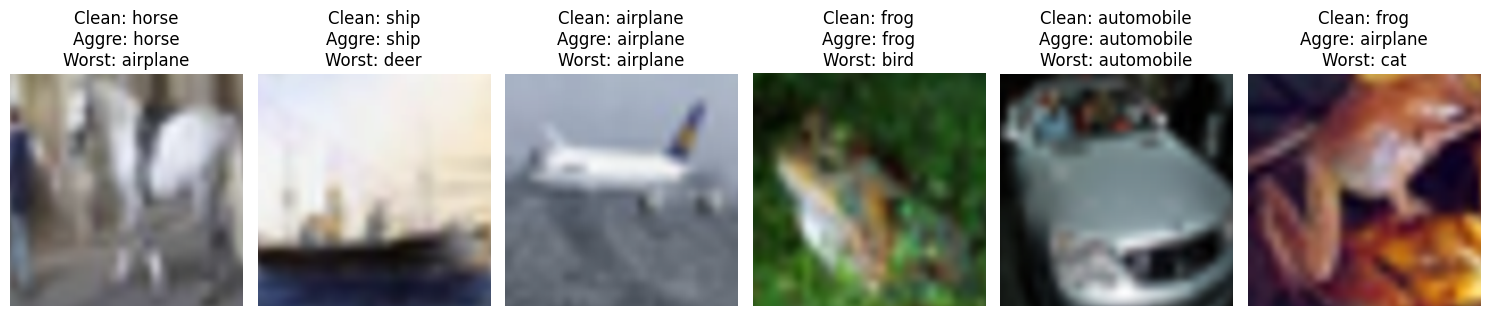

In [ ]:
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

def show_image(img):
    img = img.permute(1, 2, 0).numpy()
    
    img = (img * std) + mean
    
    img = np.clip(img, 0, 1)
    plt.imshow(img)
    plt.axis("off")

def visualize_samples(indices):
    plt.figure(figsize=(15, 4))

    for i, idx in enumerate(indices):
        img, _ = trainset[idx]

        plt.subplot(1, len(indices), i + 1)
        show_image(img)

        plt.title(
            f"Clean: {classes[noise_file['clean_label'][idx]]}\n"
            f"Aggre: {classes[noise_file['aggre_label'][idx]]}\n"
            f"Worst: {classes[noise_file['worse_label'][idx]]}"
        )

    plt.tight_layout()
    plt.show()

sample_indices = np.random.choice(50000, 6, replace=False)
visualize_samples(sample_indices)

* Load the Embeeding model based on 'FEAT' to extract features of the images we have.

In [ ]:
def load_embedding_model(mode: str=FEAT):
    if mode == "dinov2":
        model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14')
    elif mode == "imagenet":
        model = vit_b_16(weights="DEFAULT")
        model.heads = torch.nn.Sequential()
    else:
        raise NotImplementedError

    model = model.cuda()
    model.eval()
    print(next(model.parameters(), torch.tensor([])).device)
    print(model)

    return model

In [ ]:
embd = load_embedding_model()

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 264MB/s]


cuda:0
DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (blocks): ModuleList(
    (0-11): 12 x NestedTensorBlock(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): MemEffAttention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScale()
      (drop_path2): Identity()
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwi

In [ ]:
# Extract features and labels for training
with torch.no_grad():
    train_feats = []
    train_labels = []
    for img, label in tqdm.tqdm(train_loader):
        img= img.cuda()

        feats = embd(img)

        train_feats.extend(feats.cpu().numpy())
        train_labels.extend(label.numpy())

print(f"Training dataset (Num of feats, Num of labels): {len(train_feats)}, {len(train_labels)}")

100%|██████████| 12500/12500 [04:13<00:00, 49.26it/s]

Training dataset (Num of feats, Num of labels): 50000, 50000


In [ ]:
# Extract features and labels for testing
with torch.no_grad():
    test_feats = []
    test_labels = []
    for img, label in tqdm.tqdm(test_loader):
        img= img.cuda()

        feats = embd(img)

        test_feats.extend(feats.cpu().numpy())
        test_labels.extend(label.numpy())

print(f"Test datasets (Num of feats, Num of labels): {len(test_feats)}, {len(test_labels)}")

100%|██████████| 2500/2500 [00:50<00:00, 49.38it/s]

Test datasets (Num of feats, Num of labels): 10000, 10000


In [ ]:
with h5py.File(f'cifar_feats_{FEAT}.h5', 'w') as f:
    f.create_dataset('train_feats', data=train_feats)
    f.create_dataset('train_labels', data=train_labels)
    f.create_dataset('test_feats', data=test_feats)
    f.create_dataset('test_labels', data=test_labels)

In [ ]:
def load_cifardataset(
    cifar10n_pt: str= cifar10n_pt,
    cifar_h5: str = cifar_h5,
    noise_type: int = NOISE_TYPE,
    subset_length: int = SUBSET_LENGTH
):
    """
    Load cifar10-N dataset with the extracted feature vectors for the images
    """
    noise_file = torch.load(cifar10n_pt, weights_only=False)
    clean_label = noise_file['clean_label']
    worst_label = noise_file['worse_label']
    aggre_label = noise_file['aggre_label']
    random_label1 = noise_file['random_label1']
    random_label2 = noise_file['random_label2']
    random_label3 = noise_file['random_label3']

    with h5py.File(cifar_h5, "r") as f:
        X, X_test, y, y_test = f['train_feats'], f['test_feats'], f['train_labels'], f['test_labels']
        X, X_test, y, y_test = np.array(X), np.array(X_test), np.array(y), np.array(y_test)

    if noise_type == 'clean':
        y = clean_label
    elif noise_type == 'aggre':
        y = aggre_label
    elif noise_type == 'random1':
        y = random_label1
    elif noise_type == 'random2':
        y = random_label2
    elif noise_type == 'random3':
        y = random_label3
    elif noise_type == 'worst':
        y = worst_label
    else:
        print('Noise type not recognized.')

    X = pd.DataFrame(X)
    X_test = pd.DataFrame(X_test)
    y = pd.Series(y)
    y_test = pd.Series(y_test)

    noisy = [0 if clean_label[x] == y[x] else 1 for x in range(subset_length)]
    gt = np.where(np.array(noisy)==1)[0] # Get indices of noisy samples
    a, b = np.unique(y[:subset_length], return_counts=True)
    print(f"Labels distribution: {b}")
    X = X[:subset_length]
    y = y[:subset_length]

    print(f"Number of noisy samples: {np.sum(noisy)}")

    return X, y, X_test, y_test, noisy, gt, clean_label, a, b

In [ ]:
X, y, X_test, y_test, noisy, gt, clean_label, a, b = load_cifardataset(cifar10n_pt, cifar_h5, NOISE_TYPE, SUBSET_LENGTH)
X.shape,len(y), X_test.shape, len(y_test)

Labels distribution: [5314 5509 5407 4621 4349 4963 4616 5003 5347 4871]
Number of noisy samples: 4505


((50000, 384), 50000, (10000, 384), 10000)

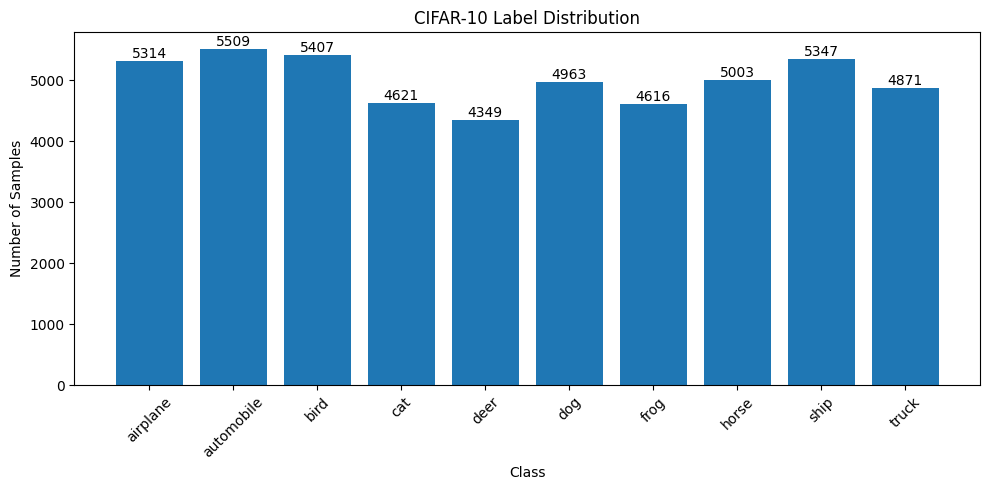

In [ ]:
class_names = [classes[i] for i in a]
plt.figure(figsize=(10, 5))
bars = plt.bar(class_names, b)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

plt.title("CIFAR-10 Label Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
X.iloc[0], y[0]

(0     -2.938764
 1     -3.180794
 2      2.806179
 3     -1.525123
 4      0.708352
          ...   
 379    1.075058
 380   -4.254154
 381   -2.890453
 382   -1.980162
 383    0.609566
 Name: 0, Length: 384, dtype: float32,
 np.int64(6))

## ReCov Model

* ReCov is not a neural layer/model. It is a repeated cross-validation workflow: train one classifier per fold, find the worst validation fold, count samples that repeatedly appear in worst folds, then mark high-count samples as likely noisy.

![ReCov](https://github.com/GJiananChen/ReCoV/blob/master/images/recov.JPG?raw=true)

Input:
  Dataset D
  Number of folds k
  Number of repeated runs R
  Base supervised model f

Initialize:
  counts[i] = 0 for every sample i

For run r = 1,...,R:
  1. Randomly split D into k folds
  2. For each fold j:
       train model f on D excluding fold j
       evaluate f on validation fold j
  3. Find the worst validation fold:
       W_r = fold with minimum validation accuracy
  4. For every sample i in W_r:
       counts[i] += 1

Output:
  counts[i] = how often sample i appeared in the worst fold

## Training ReCov on Mushroom Dataset

In [ ]:

file_path = 'mushrooms.csv'
url = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/mushrooms.csv'

if not os.path.exists(file_path):
    print("Downloading the Mushroom dataset...")
    urllib.request.urlretrieve(url, file_path)
    print("Download finished successfully.")
else:
    print("The file is already in your working directory.")


mushroom = pd.read_csv(file_path)


n_samples = mushroom.shape[0]
print(f"Total samples: {n_samples}")
assert n_samples == 8124, "Error: The sample count does not match the research paper."


n_features_original = mushroom.shape[1] - 1
print(f"Number of original categorical features: {n_features_original}")
assert n_features_original == 22, "Error: The number of original features does not match the research paper."


cols = mushroom.columns.to_list()
target_col = 'type' if 'type' in cols else 'class'
cols.remove(target_col)

The file is already in your working directory.


Total samples: 8124
Number of original categorical features: 22


## Utility Functions

This is a set of helper functions for simple calculations and list operations:

* **`closest_value`**: Finds the number in a list that is numerically closest to a specific target value.
* **`pbinom`**: Calculates the cumulative probability (CDF) for a binomial distribution (e.g., what is the probability of getting "heads" 5 times out of 10 coin flips).
* **`qbinom`**: Acts as the reverse of `pbinom`; it calculates how many successes are needed to reach a specific target probability.
* **`smallest_index`**: Finds the smallest number in a list and returns its exact position (index) rather than the value itself.

In [ ]:
def closest_value(input_list, input_value):
    """Finds the value in the list closest to the input_value."""
    difference = lambda x: abs(x - input_value)
    return min(input_list, key=difference)

def pbinom(q, size, prob=0.5):
    """Calculates the cumulative distribution function (CDF) for a binomial distribution."""
    from scipy.stats import binom
    return binom.cdf(k=q, n=size, p=prob, loc=0)

def qbinom(q, size, prob=0.5):
    """Calculates the percent point function (quantile function) for a binomial distribution."""
    from scipy.stats import binom
    return binom.ppf(q=q, n=size, p=prob, loc=0)

def smallest_index(lst):
    """Returns the index of the smallest value in the list."""
    return lst.index(min(lst))

## Data Loading

In [ ]:


mushroom = pd.read_csv('mushrooms.csv')


target_col = 'type' if 'type' in mushroom.columns else 'class'

cols = mushroom.columns.to_list()
cols.remove(target_col)


mushroom = pd.get_dummies(mushroom, columns=cols)


X = mushroom.drop([target_col], axis=1).copy()
y = mushroom[target_col].copy()


y[y == 'p'] = 1
y[y == 'e'] = 0
y = y.astype('int').to_list()
y = pd.Series(y)

print(f"Data processed successfully: {X.shape[0]} samples and {X.shape[1]} features.")

Data processed successfully: 8124 samples and 117 features.


## Function: `run_single_iteration`

This function executes a single "testing round" on the dataset to hunt for potentially noisy or mislabeled samples. Because it is self-contained, it is designed to be run thousands of times simultaneously (in parallel) to speed up the process.

**How it works step-by-step:**
1. **Random Splitting:** It shuffles the dataset and splits it into 5 equal parts (folds).
2. **Training & Testing:** It trains an AI model (Logistic Regression) 5 times. Each time, it learns from 4 parts and tests itself on the 5th part.
3. **Evaluation:** It calculates the model's performance score (using the AUC metric) for each test part.
4. **Finding the Worst:** It identifies the specific part (fold) that received the **worst performance score**, and returns the exact IDs of the samples in that part, flagging them as suspected noisy labels.

In [ ]:
def run_single_iteration(random_state, X_data, y_data):
    """Executes a single cross-validation iteration to be run in parallel."""
    from sklearn.model_selection import KFold
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score

    kf = KFold(n_splits=5, random_state=random_state, shuffle=True)
    aucs = []
    test_ids = []

    for train_idx, test_idx in kf.split(X_data, y_data):
        X_train, X_test = X_data.iloc[train_idx], X_data.iloc[test_idx]
        y_train, y_test = y_data.iloc[train_idx].to_list(), y_data.iloc[test_idx].to_list()


        lr = LogisticRegression(max_iter=1000, solver='lbfgs')
        lr.fit(X_train, y_train)

        y_pred = lr.predict(X_test)
        auc = roc_auc_score(y_test, y_pred)

        aucs.append(auc)
        test_ids.append(test_idx)


    return test_ids[smallest_index(aucs)]


## Main Experiment Loop

This code represents the core pipeline of the experiment, executing the ReCoV algorithm from start to finish to detect mislabeled data.

**The process is broken down into 5 sequential steps:**

1. **Noise Injection:** It takes a clean copy of the data and randomly flips a specific percentage of labels (10% then 20%) to simulate real-world human errors.
2. **Parallel Execution:** It runs the testing function (`run_single_iteration`) 50,000 times. To prevent system crashes, the runs are divided into smaller batches and distributed across 12 CPU cores for maximum speed.
3. **Statistical Analysis:** It tallies how many times each sample ended up in the "worst performing" group, then applies statistical rules to set a strict threshold separating clean data from noisy data.
4. **Plotting & Evaluation:** It visualizes the distribution using a histogram and calculates the algorithm's precision (i.e., how many of the injected noisy labels were successfully caught).
5. **Retraining:** Finally, it discards all the flagged noisy samples and trains a fresh model on the newly cleaned data to prove that the final accuracy reaches 100%.


Starting ReCoV experiment with noise ratio: 10%
Noise successfully injected (812 samples).
Beginning parallel execution (50000 runs using 12 cores)...
Progress: 1000 / 50000 runs
Progress: 2000 / 50000 runs
Progress: 3000 / 50000 runs
Progress: 4000 / 50000 runs
Progress: 5000 / 50000 runs
Progress: 6000 / 50000 runs
Progress: 7000 / 50000 runs
Progress: 8000 / 50000 runs
Progress: 9000 / 50000 runs
Progress: 10000 / 50000 runs
Progress: 11000 / 50000 runs
Progress: 12000 / 50000 runs
Progress: 13000 / 50000 runs
Progress: 14000 / 50000 runs
Progress: 15000 / 50000 runs
Progress: 16000 / 50000 runs
Progress: 17000 / 50000 runs
Progress: 18000 / 50000 runs
Progress: 19000 / 50000 runs
Progress: 20000 / 50000 runs
Progress: 21000 / 50000 runs
Progress: 22000 / 50000 runs
Progress: 23000 / 50000 runs
Progress: 24000 / 50000 runs
Progress: 25000 / 50000 runs
Progress: 26000 / 50000 runs
Progress: 27000 / 50000 runs
Progress: 28000 / 50000 runs
Progress: 29000 / 50000 runs
Progress: 30000 

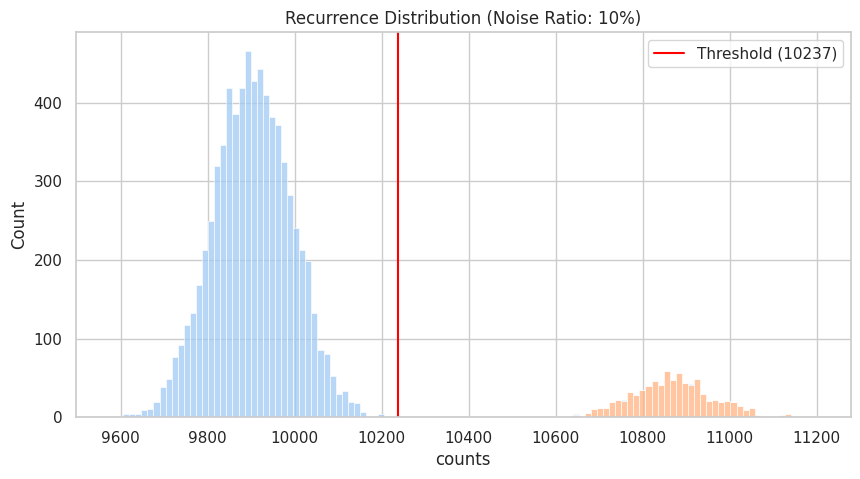


Noise detection results: Precision (NEP) = 812 / 812
Final Averages: Accuracy=1.000, AUC=1.000


Starting ReCoV experiment with noise ratio: 20%
Noise successfully injected (1624 samples).
Beginning parallel execution (50000 runs using 12 cores)...
Progress: 1000 / 50000 runs
Progress: 2000 / 50000 runs
Progress: 3000 / 50000 runs
Progress: 4000 / 50000 runs
Progress: 5000 / 50000 runs
Progress: 6000 / 50000 runs
Progress: 7000 / 50000 runs
Progress: 8000 / 50000 runs
Progress: 9000 / 50000 runs
Progress: 10000 / 50000 runs
Progress: 11000 / 50000 runs
Progress: 12000 / 50000 runs
Progress: 13000 / 50000 runs
Progress: 14000 / 50000 runs
Progress: 15000 / 50000 runs
Progress: 16000 / 50000 runs
Progress: 17000 / 50000 runs
Progress: 18000 / 50000 runs
Progress: 19000 / 50000 runs
Progress: 20000 / 50000 runs
Progress: 21000 / 50000 runs
Progress: 22000 / 50000 runs
Progress: 23000 / 50000 runs
Progress: 24000 / 50000 runs
Progress: 25000 / 50000 runs
Progress: 26000 / 50000 runs
Progr

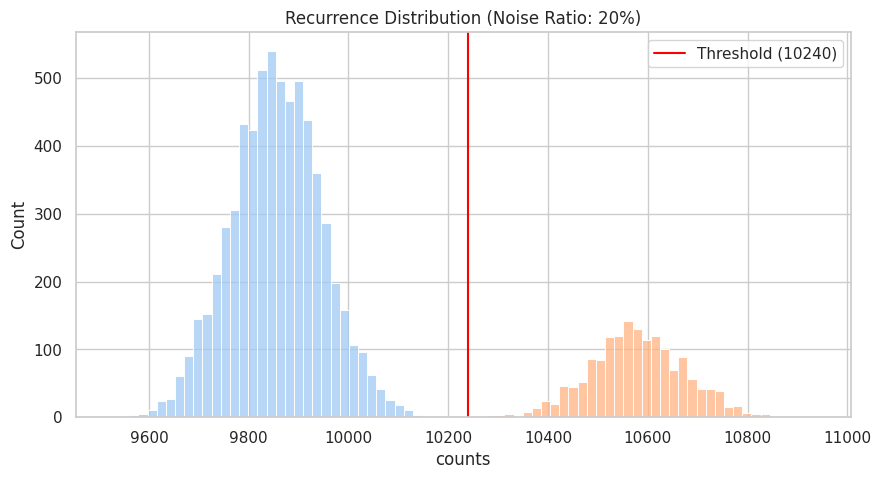


Noise detection results: Precision (NEP) = 1623 / 1624
Final Averages: Accuracy=1.000, AUC=1.000



In [5]:
from joblib import Parallel, delayed


y_original = y.copy()
NOISE_RATIOS = [10, 20]
n_runs = 50000
batch_size = 1000

for NOISE_RATIO in NOISE_RATIOS:

    print(f"Starting ReCoV experiment with noise ratio: {NOISE_RATIO}%")



    random.seed(1)
    np.random.seed(1)
    y_experiment = y_original.copy()
    noisy = random.sample(list(enumerate(y_experiment)), int(0.01 * NOISE_RATIO * len(y_experiment)))
    gt = [x[0] for x in noisy]

    for index, label in noisy:
        y_experiment[index] = 1 - label

    noisy_labels = [1 if x in gt else 0 for x in list(range(len(y_experiment)))]
    print(f"Noise successfully injected ({len(noisy)} samples).")


    all_candidates = np.array([], dtype='int')
    print(f"Beginning parallel execution ({n_runs} runs using 12 cores)...")

    for i in range(0, n_runs, batch_size):
        current_batch_runs = min(batch_size, n_runs - i)

        batch_results = Parallel(n_jobs=12)(
            delayed(run_single_iteration)(rs, X, y_experiment) for rs in range(i + 1, i + current_batch_runs + 1)
        )
        all_candidates = np.concatenate([all_candidates, np.concatenate(batch_results)])
        print(f"Progress: {i + current_batch_runs} / {n_runs} runs")


    ids, counts = np.unique(all_candidates, return_counts=True)
    pvalues = [1 - pbinom(x, n_runs, 0.2) for x in counts]
    reject, corrected_pvalues, _, _ = multipletests(pvalues, alpha=0.05, method='fdr_bh')

    p = pvalues[np.where(corrected_pvalues == closest_value(corrected_pvalues, 0.05))[0][0]]
    corrected_threshold = qbinom(1 - p, n_runs, 0.2)

    outlier_df = pd.DataFrame({
        'ids': ids, 'counts': counts, 'pvalues': pvalues,
        'corrected': corrected_pvalues, 'noisy_label': noisy_labels
    })


    plt.figure(figsize=(10, 5))
    sns.set_theme(style="whitegrid")
    ax = sns.histplot(data=outlier_df, x='counts', stat='count', multiple="stack",
                      kde=False, palette="pastel", hue="noisy_label", element="bars")
    plt.axvline(int(corrected_threshold), color='red', linestyle='-', label=f'Threshold ({int(corrected_threshold)})')
    plt.title(f'Recurrence Distribution (Noise Ratio: {NOISE_RATIO}%)')
    plt.legend()
    plt.show()


    identified = np.where(counts > corrected_threshold)[0].tolist()
    F, M = set(identified), set(gt)
    print(f"Noise detection results: Precision (NEP) = {len(F.intersection(M))} / {len(M)}")


    F_t = set(range(0, len(y_experiment))) - set(identified)
    y_clean = y_experiment.loc[list(F_t)].copy()
    X_clean = X.loc[list(F_t)].copy()

    aucs_clean, accs_clean = [], []
    kf = KFold(n_splits=5, random_state=42, shuffle=True)

    for train_idx, test_idx in kf.split(X_clean, y_clean):
        lr = LogisticRegression(max_iter=1000, solver='lbfgs')
        lr.fit(X_clean.iloc[train_idx], y_clean.iloc[train_idx].to_list())
        y_pred = lr.predict(X_clean.iloc[test_idx])
        aucs_clean.append(roc_auc_score(y_clean.iloc[test_idx], y_pred))
        accs_clean.append(accuracy_score(y_clean.iloc[test_idx], y_pred))

    print(f'Final Averages: Accuracy={sum(accs_clean)/len(accs_clean):.3f}, AUC={sum(aucs_clean)/len(aucs_clean):.3f}\n')

## Training ReCov on CIFAR-10N Dataset

In [ ]:

N_RUNS: int = 100
K_FOLDS: int = 5
TAU: float = 0.1

N = len(X)
print(f"Dataset: N={N}, k={K_FOLDS}, runs={N_RUNS}")

Dataset: N=50000, k=5, runs=100


In [ ]:
def to_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    if hasattr(x, "to_numpy"):
        return x.to_numpy()
    return np.asarray(x)

In [ ]:
def build_recov_base_model(random_state=RANDOM_STATE):
    """
    Base classifier used inside each ReCov fold.
    The paper use logistic regression on extracted features.
    """
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            solver="lbfgs",
            n_jobs=-1,
            random_state=random_state
        )
    )


In [ ]:
def run_one_recov(
    X,
    y,
    seed,
    n_folds=5,
    estimator=None,
):
    X_np = to_numpy(X)
    y_np = to_numpy(y).astype(int)

    if estimator is None:
        estimator = build_recov_base_model(seed)

    splitter = StratifiedKFold(
        n_splits=n_folds,
        shuffle=True,
        random_state=seed
    )
    splits = splitter.split(X_np, y_np)

    fold_accs = []
    fold_val_ids = []

    for fold_id, (train_idx, val_idx) in enumerate(splits):
        model = clone(estimator)
        model.fit(X_np[train_idx], y_np[train_idx])

        y_pred = model.predict(X_np[val_idx])
        acc = accuracy_score(y_np[val_idx], y_pred)

        fold_accs.append(acc)
        fold_val_ids.append(val_idx)

    worst_fold = int(np.argmin(fold_accs))

    return {
        "seed": seed,
        "fold_accs": fold_accs,
        "worst_fold": worst_fold,
        "worst_acc": fold_accs[worst_fold],
        "mean_acc": float(np.mean(fold_accs)),
        "worst_ids": fold_val_ids[worst_fold],
    }


In [ ]:
def fit_recov(
    X,
    y,
    n_runs=30,
    n_folds=5,
    random_state=RANDOM_STATE,
):
    """
    ReCov training:
    repeat k-fold CV with different seeds,
    collect samples from the worst validation fold each run,
    count how often every sample appears in a worst fold.
    """
    rng = np.random.default_rng(random_state)
    seeds = rng.integers(0, np.iinfo(np.int32).max, size=n_runs)

    counts = np.zeros(len(y), dtype=int)
    history = []

    base_model = build_recov_base_model(random_state)

    for run_id, seed in enumerate(tqdm.tqdm(seeds, desc="Running ReCov")):
        result = run_one_recov(
            X=X,
            y=y,
            seed=int(seed),
            n_folds=n_folds,
            estimator=base_model
        )

        counts[result["worst_ids"]] += 1

        history.append({
            "run": run_id,
            "seed": int(seed),
            "worst_fold": result["worst_fold"],
            "worst_acc": result["worst_acc"],
            "mean_acc": result["mean_acc"],
            "fold_accs": result["fold_accs"],
        })

    return counts, pd.DataFrame(history)

### ReCov Training & Evaluation

In [ ]:
recov_counts, recov_history = fit_recov(
    X=X,
    y=y,
    n_runs=N_RUNS,
    n_folds=K_FOLDS,
    random_state=RANDOM_STATE
)

Running ReCov: 100%|██████████| 100/100 [1:01:18<00:00, 36.78s/it]


In [ ]:
recov_counts, recov_counts.max()

(array([14, 19, 16, ..., 24, 17, 21], shape=(50000,)), np.int64(37))

In [ ]:
recov_history.tail(10)

,run,seed,worst_fold,worst_acc,mean_acc,fold_accs
90,90,934620676,2,0.8809,0.88684,"[0.8904, 0.885, 0.8809, 0.8876, 0.8903]"
91,91,1728218297,1,0.8848,0.88720,"[0.8864, 0.8848, 0.888, 0.8854, 0.8914]"
92,92,1807519524,4,0.8827,0.88652,"[0.8873, 0.8834, 0.894, 0.8852, 0.8827]"
93,93,832103482,0,0.8836,0.88712,"[0.8836, 0.8895, 0.8868, 0.8882, 0.8875]"
94,94,1928628490,0,0.8850,0.88742,"[0.885, 0.8925, 0.8853, 0.8869, 0.8874]"
95,95,619179887,0,0.8850,0.88744,"[0.885, 0.886, 0.8875, 0.8863, 0.8924]"
96,96,514446424,1,0.8848,0.88686,"[0.8885, 0.8848, 0.8873, 0.8888, 0.8849]"
97,97,1465647933,1,0.8838,0.88684,"[0.8898, 0.8838, 0.8903, 0.8841, 0.8862]"
98,98,1367435607,4,0.8834,0.88666,"[0.8864, 0.8881, 0.8851, 0.8903, 0.8834]"
99,99,300116172,2,0.8835,0.88672,"[0.8865, 0.8839, 0.8835, 0.8858, 0.8939]"


* 1. thesholding method of largest gap

In [ ]:
def identify_noisy_by_largest_gap(counts):
    """
    Parameter-free ReCov separation:
    if repeated runs separate clean/noisy count distributions,
    the largest empty gap in occurrence counts becomes the cutoff.
    """
    counts = np.asarray(counts)
    unique_counts = np.unique(counts)

    if len(unique_counts) < 2:
        return np.array([], dtype=int), None

    gaps = np.diff(unique_counts)
    best_gap_idx = int(np.argmax(gaps))
    threshold = unique_counts[best_gap_idx + 1]

    identified = np.where(counts >= threshold)[0]
    return identified.astype(int), int(threshold)

def identify_top_k_by_known_noise_count(counts, gt):
    k = len(gt)
    if k == 0:
        return np.array([], dtype=int)
    return np.argsort(counts)[-k:].astype(int)

identified_recov_auto, recov_threshold = identify_noisy_by_largest_gap(recov_counts)
identified_recov_topk = identify_top_k_by_known_noise_count(recov_counts, gt)

print(f"ReCov runs: {N_RUNS}")
print(f"ReCov threshold from largest gap: {recov_threshold}")
print(f"Auto identified noisy samples: {len(identified_recov_auto)}")
print(f"Top-k evaluation identified samples: {len(identified_recov_topk)}")

ReCov runs: 100
ReCov threshold from largest gap: 7
Auto identified noisy samples: 49996
Top-k evaluation identified samples: 4505


In [ ]:
def noise_detection_metrics(identified, gt, n_samples):
    identified = set(map(int, identified))
    true_noisy = set(map(int, gt))
    all_ids = set(range(n_samples))

    true_clean = all_ids - true_noisy

    tp = len(identified & true_noisy)
    fp = len(identified & true_clean)
    fn = len(true_noisy - identified)
    tn = len(true_clean - identified)

    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0

    return {
        "identified": len(identified),
        "true_noisy": len(true_noisy),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "precision": precision,
        "recall": recall,
        "F1": f1,
    }

metrics_auto = noise_detection_metrics(identified_recov_auto, gt, len(y))
metrics_topk = noise_detection_metrics(identified_recov_topk, gt, len(y))

pd.DataFrame(
    [metrics_auto, metrics_topk],
    index=["ReCov auto largest-gap", "ReCov top-k evaluation"]
)

,identified,true_noisy,TP,FP,FN,TN,precision,recall,F1
ReCov auto largest-gap,49996,4505,4505,45491,0,4,0.090107,1.000000,0.165318
ReCov top-k evaluation,4505,4505,490,4015,4015,41480,0.108768,0.108768,0.108768


-> we can see that thresholding method with largets gap method is too bad even with 100 repitions

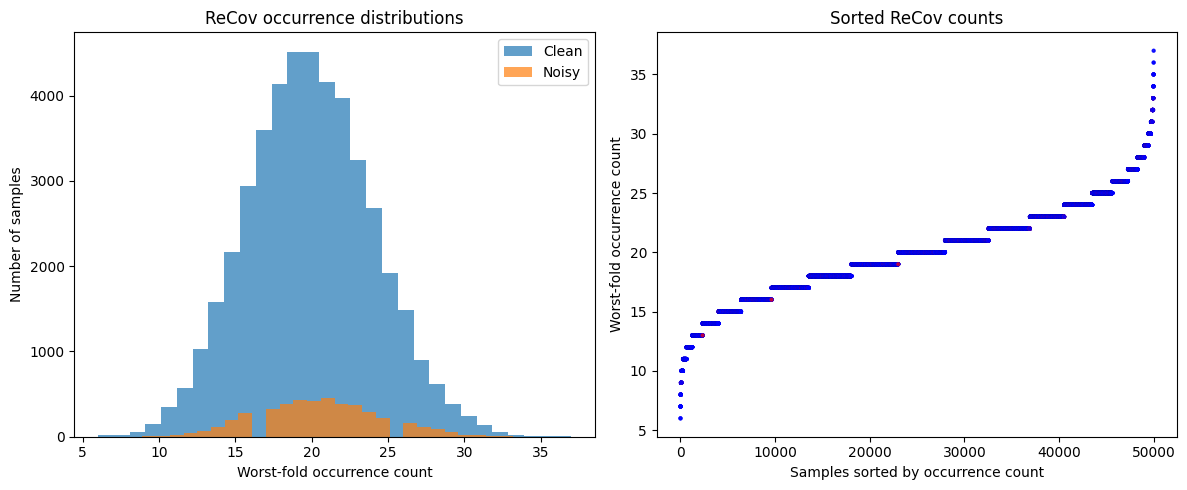

In [ ]:
def plot_recov_occurrences(counts, gt):
    gt_mask = np.zeros(len(counts), dtype=bool)
    gt_mask[np.asarray(gt, dtype=int)] = True

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.hist(counts[~gt_mask], bins=30, alpha=0.7, label="Clean")
    plt.hist(counts[gt_mask], bins=30, alpha=0.7, label="Noisy")
    plt.xlabel("Worst-fold occurrence count")
    plt.ylabel("Number of samples")
    plt.title("ReCov occurrence distributions")
    plt.legend()

    plt.subplot(1, 2, 2)
    order = np.argsort(counts)
    colors = np.where(gt_mask[order], "red", "blue")
    plt.scatter(np.arange(len(counts)), counts[order], c=colors, s=4, alpha=0.6)
    plt.xlabel("Samples sorted by occurrence count")
    plt.ylabel("Worst-fold occurrence count")
    plt.title("Sorted ReCov counts")

    plt.tight_layout()
    plt.show()

plot_recov_occurrences(recov_counts, gt)

In [ ]:
def evaluate_training_strategy(name, X_train, y_train, X_test, y_test):
    model = build_recov_base_model(RANDOM_STATE)
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)

    return {
        "strategy": name,
        "n_train": len(y_train),
        "test_accuracy": acc
    }

X_np = to_numpy(X)
y_noisy_np = to_numpy(y).astype(int)
X_test_np = to_numpy(X_test)
y_test_np = to_numpy(y_test).astype(int)

clean_label_np = to_numpy(clean_label).astype(int)[:len(y_noisy_np)]

auto_keep_mask = np.ones(len(y_noisy_np), dtype=bool)
auto_keep_mask[identified_recov_auto] = False

topk_keep_mask = np.ones(len(y_noisy_np), dtype=bool)
topk_keep_mask[identified_recov_topk] = False

gt_keep_mask = np.ones(len(y_noisy_np), dtype=bool)
gt_keep_mask[np.asarray(gt, dtype=int)] = False

results = []

results.append(
    evaluate_training_strategy(
        "Upper bound: clean labels",
        X_np,
        clean_label_np,
        X_test_np,
        y_test_np
    )
)

results.append(
    evaluate_training_strategy(
        "Baseline: noisy labels",
        X_np,
        y_noisy_np,
        X_test_np,
        y_test_np
    )
)

results.append(
    evaluate_training_strategy(
        "ReCov cleaned: auto largest-gap",
        X_np[auto_keep_mask],
        y_noisy_np[auto_keep_mask],
        X_test_np,
        y_test_np
    )
)

results.append(
    evaluate_training_strategy(
        "ReCov cleaned: top-k evaluation",
        X_np[topk_keep_mask],
        y_noisy_np[topk_keep_mask],
        X_test_np,
        y_test_np
    )
)

results.append(
    evaluate_training_strategy(
        "Oracle: ground-truth noisy removed",
        X_np[gt_keep_mask],
        y_noisy_np[gt_keep_mask],
        X_test_np,
        y_test_np
    )
)

pd.DataFrame(results).sort_values("test_accuracy", ascending=False)

,strategy,n_train,test_accuracy
0,Upper bound: clean labels,50000,0.9664
4,Oracle: ground-truth noisy removed,45495,0.9661
1,Baseline: noisy labels,50000,0.9522
3,ReCov cleaned: top-k evaluation,45495,0.9501
2,ReCov cleaned: auto largest-gap,4,0.3264


NOTE: Full ReCoV works best when the worst validation fold clearly corresponds to the fold with more noisy labels. On CIFAR-10N with strong DINOv2/ViT features and logistic regression, fold accuracies are very close. In our notebook they are around 0.88-0.89, so the “worst fold” signal is weak and noisy. That means plain ReCoV counts do not separate clean and noisy samples well.

## FastReCov Model

![FastReCov](https://github.com/GJiananChen/ReCoV/blob/master/images/fastrecov.JPG?raw=true)

     NOTE: Important difference:
    
            - ReCoV: higher count = more suspicious
            - FastReCoV: lower memory = more suspicious



In [ ]:

FASTRECOV_RUNS: int = 10
FASTRECOV_FOLDS: int = 5
FASTRECOV_TAU: int = 0.1
FASTRECOV_MEMORY_THRESHOLD: float = 0.3
FASTRECOV_NOISY_DROP: float = 0.8
FASTRECOV_EMA_NEW: float = 0.3


#### weighted sampling

In [ ]:
def get_sample_probs(weights: np.ndarray, tau: float) -> np.ndarray:
    """
    Official ReCoV weighted sampling probability:
    p_i = softmax(memory / tau)
    """
    weights = np.asarray(weights, dtype=float)
    z = weights / tau
    z = z - np.max(z)  # numerical stability; equivalent softmax
    exp_i = np.exp(z)
    return exp_i / np.sum(exp_i)


def sample_folds(n_folds: int, weights: np.ndarray, tau: float):
    """
    Same fold construction idea as official sample.py:
    high-memory samples go to the 'best' side,
    low-memory samples accumulate in the 'worst' side.
    """
    n_samples = len(weights)
    fold_id = {"best": [], "rest": [], "worst": []}

    p_i = get_sample_probs(weights, tau)

    if tau < 0.0001:
        ordering = np.argsort(weights)[::-1]
    elif tau > 10000:
        ordering = np.random.permutation(n_samples)
    else:
        ordering = np.random.choice(
            n_samples,
            size=n_samples,
            replace=False,
            p=p_i
        )

    fold_size = int(n_samples / n_folds)

    fold_id["best"] = ordering[:fold_size]
    fold_id["rest"] = ordering[fold_size:(n_folds - 1) * fold_size]
    fold_id["worst"] = ordering[(n_folds - 1) * fold_size:]

    rest_ids = fold_id["rest"]
    rest_fold_size = int(np.ceil(len(rest_ids) / (n_folds - 2)))

    rest_folds = [
        rest_ids[i * rest_fold_size:(i + 1) * rest_fold_size]
        for i in range(n_folds - 2)
    ]

    folds = [fold_id["best"]] + rest_folds + [fold_id["worst"]]

    fold_splits = []
    for i in range(n_folds):
        temp = folds.copy()
        test_ids = np.random.permutation(temp.pop(i))
        train_ids = np.random.permutation(np.concatenate(temp))
        fold_splits.append((train_ids, test_ids))

    return fold_splits, fold_id

In [ ]:
def train_one_fastrecov_run(
    X,
    y,
    fold_splits,
    filter_noise=False,
    noisy_idx=None,
):
    """
    Official CIFAR FastReCoV training step:
    train one LogisticRegression per fold and collect validation probabilities.
    """
    if noisy_idx is None:
        noisy_idx = []

    accs = []
    test_ids = []
    pred_probs = []
    test_labels = []

    for fold, (train_idx, test_idx) in enumerate(fold_splits):
        train_idx = np.asarray(train_idx, dtype=int)
        test_idx = np.asarray(test_idx, dtype=int)

        if filter_noise and len(noisy_idx) > 0:
            drop_idx = np.random.permutation(noisy_idx)[
                :int(FASTRECOV_NOISY_DROP * len(noisy_idx))
            ]
            train_idx = np.array(list(set(train_idx) - set(drop_idx)), dtype=int)

        X_train = X.iloc[train_idx]
        X_val = X.iloc[test_idx]
        y_train = y.iloc[train_idx].to_list()
        y_val = y.iloc[test_idx].to_list()

        model = LogisticRegression()
        model.fit(X_train, y_train)

        y_pred = model.predict(X_val)
        probs = model.predict_proba(X_val)

        acc = accuracy_score(y_val, y_pred)

        accs.append(acc)
        test_ids.append(test_idx)
        pred_probs.append(probs)
        test_labels.append(y_val)

    return accs, test_ids, pred_probs, test_labels

In [ ]:
def rank_weights_fastrecov(test_ids, pred_probs, test_labels, memory):
    """
    Official CIFAR FastReCoV ranking:
    sample metric = predicted probability of the observed/noisy label.
    Lower memory means more suspicious.
    """
    test_ids_all = np.concatenate(test_ids)
    pred_probs_all = np.concatenate(pred_probs)
    test_labels_all = np.concatenate(test_labels).astype(int)

    row_idx = np.arange(len(test_labels_all))
    label_prob = pred_probs_all[row_idx, test_labels_all]

    # Official script:
    # weights = 1 - (temp.max() - temp)
    weights = 1 - (label_prob.max() - label_prob)

    order = np.argsort(test_ids_all)
    weights = weights[order]

    memory = FASTRECOV_EMA_NEW * weights + (1 - FASTRECOV_EMA_NEW) * memory

    return memory

In [ ]:
def fit_fastrecov_cifar(X, y):
    """
    Full FastReCoV loop for CIFAR-10N, matching the paper/official repo setup.
    """
    kf = KFold(
        n_splits=FASTRECOV_FOLDS,
        random_state=RANDOM_STATE,
        shuffle=True
    )

    fold_splits = list(kf.split(X, y))

    memory = np.zeros(len(y), dtype=float)
    identified = np.array([], dtype=int)

    history = []

    for run in tqdm.tqdm(range(FASTRECOV_RUNS), desc="Running FastReCov"):
        accs, test_ids, pred_probs, test_labels = train_one_fastrecov_run(
            X=X,
            y=y,
            fold_splits=fold_splits,
            filter_noise=True,
            noisy_idx=identified
        )

        memory = rank_weights_fastrecov(
            test_ids=test_ids,
            pred_probs=pred_probs,
            test_labels=test_labels,
            memory=memory
        )

        identified = np.where(memory <= FASTRECOV_MEMORY_THRESHOLD)[0]

        fold_splits, fold_ids = sample_folds(
            n_folds=FASTRECOV_FOLDS,
            weights=memory,
            tau=FASTRECOV_TAU
        )

        metrics = noise_detection_metrics(identified, gt, len(y))

        history.append({
            "run": run,
            "fold_accs": accs,
            "mean_fold_acc": float(np.mean(accs)),
            "identified": len(identified),
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "F1": metrics["F1"],
            "memory_min": float(memory.min()),
            "memory_mean": float(memory.mean()),
            "memory_max": float(memory.max()),
        })

        print(
            f"Run {run:02d} | accs={np.round(accs, 4)} | "
            f"identified={len(identified)} | "
            f"precision={metrics['precision']:.4f} | "
            f"recall={metrics['recall']:.4f} | "
            f"F1={metrics['F1']:.4f}"
        )

    return memory, identified, pd.DataFrame(history)

### FastReCov Training & Evaulation

In [ ]:
fastrecov_memory, identified_fastrecov, fastrecov_history = fit_fastrecov_cifar(X, y)

fastrecov_history.tail(10)

Running FastReCov:  10%|█         | 1/10 [01:09<10:27, 69.70s/it]

Run 00 | accs=[0.8829 0.8859 0.8893 0.8876 0.8892] | identified=50000 | precision=0.0901 | recall=1.0000 | F1=0.1653


Running FastReCov:  20%|██        | 2/10 [01:32<05:38, 42.31s/it]

Run 01 | accs=[0.9059 0.8967 0.8727 0.8239 0.5473] | identified=9570 | precision=0.4363 | recall=0.9267 | F1=0.5933


Running FastReCov:  30%|███       | 3/10 [02:28<05:39, 48.51s/it]

...

Running FastReCov:  90%|█████████ | 9/10 [08:04<00:55, 55.56s/it]

Run 08 | accs=[0.995  0.9951 0.9906 0.9796 0.4853] | identified=4983 | precision=0.8352 | recall=0.9239 | F1=0.8773


Running FastReCov: 100%|██████████| 10/10 [09:00<00:00, 54.05s/it]

Run 09 | accs=[0.9957 0.9949 0.9897 0.9815 0.4834] | identified=4986 | precision=0.8343 | recall=0.9234 | F1=0.8766


,run,fold_accs,mean_fold_acc,identified,precision,recall,F1,memory_min,memory_mean,memory_max
0,0,"[0.8829, 0.8859, 0.8893, 0.8876, 0.8892]",0.88698,50000,0.090100,1.000000,0.165306,1.120682e-05,0.247411,0.300000
1,1,"[0.9059, 0.8967, 0.8727, 0.8239, 0.5473]",0.80930,9570,0.436259,0.926748,0.593250,7.844773e-06,0.411531,0.510000
2,2,"[0.9864, 0.9842, 0.9761, 0.9376, 0.5153]",0.87992,5563,0.741686,0.915871,0.819627,5.491341e-06,0.547782,0.657000
3,3,"[0.9947, 0.9928, 0.9876, 0.9706, 0.498]",0.88874,5083,0.809758,0.913651,0.858573,3.843939e-06,0.646051,0.759900
4,4,"[0.9963, 0.9947, 0.9882, 0.9794, 0.4934]",0.89040,4956,0.831921,0.915205,0.871578,2.690757e-06,0.714995,0.831930
5,5,"[0.9965, 0.9926, 0.9915, 0.9785, 0.4869]",0.88920,4955,0.835318,0.918757,0.875053,1.883531e-06,0.763161,0.882351
6,6,"[0.9947, 0.9946, 0.99, 0.9818, 0.4866]",0.88954,4949,0.838351,0.920977,0.877724,1.318472e-06,0.796782,0.917646
7,7,"[0.9953, 0.993, 0.9922, 0.9826, 0.4846]",0.88954,4968,0.836755,0.922752,0.877652,9.229311e-07,0.820319,0.942352
8,8,"[0.995, 0.9951, 0.9906, 0.9796, 0.4853]",0.88912,4983,0.835240,0.923862,0.877319,6.460525e-07,0.836591,0.959646
9,9,"[0.9957, 0.9949, 0.9897, 0.9815, 0.4834]",0.88904,4986,0.834336,0.923418,0.876620,4.522467e-07,0.847886,0.971752


In [ ]:
metrics_fastrecov = noise_detection_metrics(
    identified_fastrecov,
    gt,
    len(y)
)

pd.DataFrame([metrics_fastrecov], index=["FastReCoV"])

,identified,true_noisy,TP,FP,FN,TN,precision,recall,F1
FastReCoV,4986,4505,4160,826,345,44669,0.834336,0.923418,0.87662


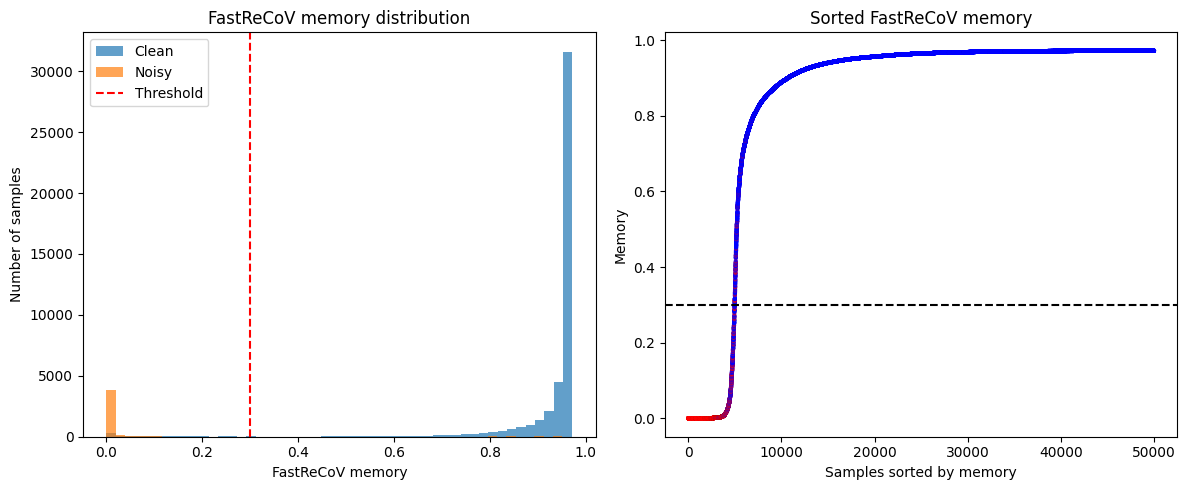

In [ ]:
def plot_fastrecov_memory(memory, gt):
    gt_mask = np.zeros(len(memory), dtype=bool)
    gt_mask[np.asarray(gt, dtype=int)] = True

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.hist(memory[~gt_mask], bins=50, alpha=0.7, label="Clean")
    plt.hist(memory[gt_mask], bins=50, alpha=0.7, label="Noisy")
    plt.axvline(FASTRECOV_MEMORY_THRESHOLD, color="red", linestyle="--", label="Threshold")
    plt.xlabel("FastReCoV memory")
    plt.ylabel("Number of samples")
    plt.title("FastReCoV memory distribution")
    plt.legend()

    plt.subplot(1, 2, 2)
    order = np.argsort(memory)
    colors = np.where(gt_mask[order], "red", "blue")
    plt.scatter(np.arange(len(memory)), memory[order], c=colors, s=4, alpha=0.6)
    plt.axhline(FASTRECOV_MEMORY_THRESHOLD, color="black", linestyle="--")
    plt.xlabel("Samples sorted by memory")
    plt.ylabel("Memory")
    plt.title("Sorted FastReCoV memory")

    plt.tight_layout()
    plt.show()


plot_fastrecov_memory(fastrecov_memory, gt)

In [ ]:
def evaluate_logreg_exact(name, X_train, y_train, X_test, y_test):
    """
    Paper-style final evaluation: LogisticRegression on frozen features.
    No StandardScaler here, to stay close to the official CIFAR script.
    """
    model = LogisticRegression()
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)

    return {
        "strategy": name,
        "n_train": len(y_train),
        "test_accuracy": acc,
        "test_accuracy_percent": acc * 100
    }


X_np = X.to_numpy()
y_noisy_np = y.to_numpy().astype(int)
X_test_np = X_test.to_numpy()
y_test_np = y_test.to_numpy().astype(int)
clean_label_np = np.asarray(clean_label).astype(int)[:len(y_noisy_np)]

fastrecov_keep_mask = np.ones(len(y_noisy_np), dtype=bool)
fastrecov_keep_mask[identified_fastrecov] = False

gt_keep_mask = np.ones(len(y_noisy_np), dtype=bool)
gt_keep_mask[np.asarray(gt, dtype=int)] = False

fastrecov_results = []

fastrecov_results.append(
    evaluate_logreg_exact(
        "Clean labels upper bound",
        X_np,
        clean_label_np,
        X_test_np,
        y_test_np
    )
)

fastrecov_results.append(
    evaluate_logreg_exact(
        "Noisy labels baseline",
        X_np,
        y_noisy_np,
        X_test_np,
        y_test_np
    )
)

fastrecov_results.append(
    evaluate_logreg_exact(
        "FastReCoV cleaned",
        X_np[fastrecov_keep_mask],
        y_noisy_np[fastrecov_keep_mask],
        X_test_np,
        y_test_np
    )
)

fastrecov_results.append(
    evaluate_logreg_exact(
        "Oracle noisy removed",
        X_np[gt_keep_mask],
        y_noisy_np[gt_keep_mask],
        X_test_np,
        y_test_np
    )
)

pd.DataFrame(fastrecov_results).sort_values("test_accuracy", ascending=False)

,strategy,n_train,test_accuracy,test_accuracy_percent
2,FastReCoV cleaned,45014,0.9651,96.51
0,Clean labels upper bound,50000,0.9642,96.42
3,Oracle noisy removed,45495,0.9641,96.41
1,Noisy labels baseline,50000,0.9526,95.26


## ReCoV vs FastReCoV

| Property | ReCoV | FastReCoV |
|----------|--------|-----------|
| **Main idea** | Repeated random k-fold cross-validation and count worst-fold occurrences. | Uses memory weights and biased sampling to identify noisy samples faster. |
| **Hyperparameters** | Mostly number of runs and folds. | Temperature, EMA weight, drop rate, threshold. |
| **Robustness** | More statistically grounded and robust. | Faster but less pure and more sensitive to tuning. |
| **Best use case** | Tabular data or pretrained embeddings. | Large datasets and expensive deep-learning pipelines. |